# Homework 1
This homework consists of 2 parts:
* Numpy (5 points)
* Matplotlib (5 points)


The score for each task is described in the comments before the task.

The task is performed independently, otherwise all those involved will receive 0 points :) If you have found a solution to any of the tasks (or part of it) in an open source, you must specify a link to this source in a separate block at the end of your work. Otherwise, **the work will also be rated at 0 points**.

## Part 1. Numpy
It is forbidden to use **while**, **for**, **if** in this part. All operations must be performed in numpy calculation. Recall that using, for example, max instead of np.max is also a suboptimal step. The solution will be counted if it satisfies the conditions above and passes asserts.

In [71]:
import numpy as np
import matplotlib.pyplot as plt
import sklearn

### Task 1 (1 point)

In [72]:
"""
description: find the largest number that comes immediately after a zero in the array
input: np.array([8, 6, 0, 3])
output: 3
"""
def max_after_zero(x: np.array) -> int:
    return np.max(x[1:][x[:-1] == 0])
    #Мы создаём два среза: x[:-1] содержит текущие элементы (без последнего числа, так как за ним больше ничего нет);
    #x[1:] включает в себя элементы, стоящие сразу после них. Условие x[:-1] == 0 находит позиции нулей, и этой маской мы выбираем из x[1:] только те числа, которые идут после нуля.
    #np.max() возвращает максимальное из них.

In [73]:
assert max_after_zero(np.array([0, 1, 2, 0, 6, 0, 10, 0])) == 10
assert max_after_zero(np.array([8, 1, 2, 0, 4, 0, 5])) == 5
assert max_after_zero(np.array([-8, -1, -2, 0, -4, 0, -5])) == -4
print("OK")

OK


### Task 2 (1 point)

In [74]:
"""
description: makes up a block matrix of four
blocks, where each block is a given matrix
"""
def block_matrix(block: np.array) -> np.array:
    horizontal = np.concatenate((block, block), axis = 1) #соединение по столбцам, ставим второй такой блок справа
    return np.concatenate((horizontal, horizontal), axis = 0) #соединение по строкам, ставим получившийся в предыдущей строке блок снизу

In [75]:
block = np.array([[1, 3, 3], [7, 0, 0]])

assert np.allclose(
    block_matrix(block),
    np.array([[1, 3, 3, 1, 3, 3],
              [7, 0, 0, 7, 0, 0],
              [1, 3, 3, 1, 3, 3],
              [7, 0, 0, 7, 0, 0]])
)
print("OK")

OK


### Task 3 (1 point)

In [76]:
"""
description: calculates the product of all
nonzero diagonal elements of a square matrix
"""
def diag_prod(matrix: np.array) -> int:
    main_diagonal = np.diag(matrix) #берем главную диагональ данной матрицы
    return np.prod(main_diagonal[main_diagonal != 0]) #создаем булеву маску: для каждого элемента проверяем, не равен ли он нулю.
                                                      #оставляем только те элементы, где маска равна True, и перемножаем их.

In [77]:
matrix = np.array([[0, 1, 2, 3],
                   [4, 5, 6, 7],
                   [8, 9, 10, 11],
                   [12, 13, 14, 15]])

assert diag_prod(matrix) == 750
print("OK")

OK


### Task 4 (1 points)

In [78]:
"""
description: this class implements StandardScaler from the sklearn library:
https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html
As input, the fit method accepts a matrix where the features are arranged in
columns, the fit method must remember mean (u) and standard deviation (s) for each of the features,
and the transform must normalize the matrix with the pre-calculated mean and standard deviation.
The transformation : z = (x - u) / s, where x - initial feature value
"""
class StandardScaler:
    def fit(self, X: np.array):
        self.mean_value = X.mean(axis = 0) #считаем среднее по каждому столбцу отдельно
        self.standard_deviation = ((X - self.mean_value)**2).mean(axis = 0) ** 0.5 #считаем стандартное отклонение каждого признака
        return self

    def transform(self, X: np.array) -> np.array:
        return (X - self.mean_value) / self.standard_deviation #из каждого значения вычитаем среднее соответствующего признака и делим на его стандартное отклонение

In [79]:
matrix = np.array([[1, 4, 4200], [0, 10, 5000], [1, 2, 1000]])
scaler = StandardScaler()

scaler.fit(matrix)

assert np.allclose(
    scaler.transform(matrix),
    np.array([[ 0.7071, -0.39223,  0.46291],
              [-1.4142,  1.37281,  0.92582],
              [ 0.7071, -0.98058, -1.38873]])
)
print("OK")

OK


### Task 5 (1 point)

In [80]:

"""
description: calculates the antiderivative polynomial (take 42 as a constant)
for example, an array of coefficients [6, 0, 1] corresponds to 6x^2 + 1
"""
def antiderivative(coefs: np.array) -> np.array:
    powers = np.arange(len(coefs), 0 , -1) #создаем массив новых степеней многочлена в обратном порядке
    coefs_new = coefs / powers #делим исходные  коэффициенты на соответствующие новые степени
    return np.concatenate((coefs_new, np.array([42]))) #добавляем в конец константу интегрирования

In [81]:
coefs = np.array([4, 6, 0, 1])

assert np.allclose(
    antiderivative(coefs),
    np.array([1., 2., 0., 1., 42.])
)
print("OK")

OK


In [82]:
coefs = np.array([1, 7, -12, 21, -6])

assert np.allclose(
    antiderivative(coefs),
    np.array([ 0.2, 1.75, -4., 10.5, -6., 42.])
)
print("OK")

OK


## Part 2. Matplotlib

Graphs should be readable without having to look into the code:
*   Graph should have a title
*   Subgraphs should have  titles
*   Axes should be labeled
*   Labels should not overlap
*   Font should be readable
*   The colors should be easily distinguishable



### Task 1 (2.5 points)
Generate a Gaussian vector of dimension 2 from 100 points (choose $\mu$ and $\sigma$ on your choice). A 2D Gaussian vector generates points in a plane following a normal distribution pattern. Each point has x and y coordinates drawn from this distribution.

In [83]:
np.random.seed(42) #фиксируем генератор случайных чисел
mu = np.array([10, 0]) #задаем математическое ожидание двумерного распределения(центр облака точек будет вокруг точки (10, 0))
sigma = 12 #задаем стандартное отклонение
data = np.random.normal(loc=mu, scale=sigma, size=(100, 2))

Check [the three sigma rule](https://en.wikipedia.org/wiki/68-95-99.7_rule): 99.7% of the values of normal distribution $\in [\mu - 3\sigma; \mu + 3\sigma]$.

Let's visually check this rule for generated 2D data. Draw:



*   The generated data;
*   Point $\mu$ in a separate color;
*   A circle centered in $\mu$ with a radius such that 0.99 of all points fall there;
*   A circle with a radius of 3 sigma;



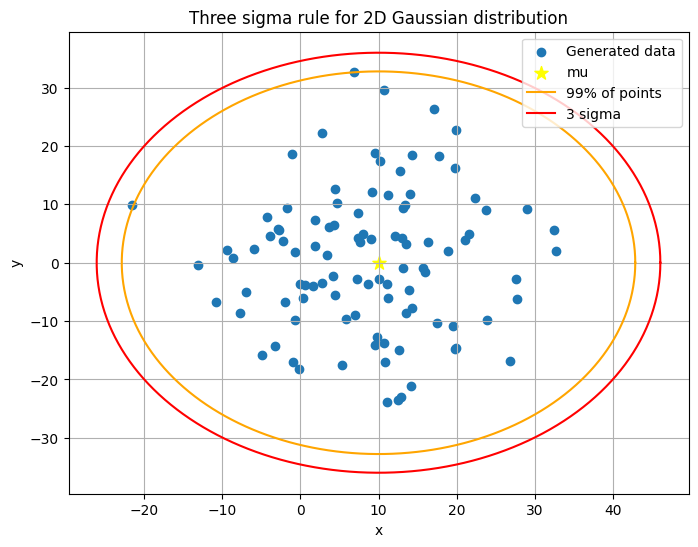

In [84]:
distances = np.sum((data - mu) ** 2, axis=1) ** 0.5 #считаем расстояние от каждой точки до центра mu по формуле евклидова расстояния
indexes = np.argpartition(distances, 98) #находим позицию 99-й ближайшей точки к центру; используем индекс 98, потому что индексация начинается с нуля
radius_99 = distances[indexes[98]] #берём расстояние до этой 99-й точки, то есть это радиус круга, который охватывает 99 из 100 точек
radius_3sigma = 3 * sigma #считаем радиус второго круга по правилу трёх сигм

angles = np.linspace(0, 2 * np.pi, 200) #создаём 200 значений угла от 0 до 2pi, то есть полный круг от 0 до 360°.
plt.figure(figsize=(8, 6))

#строим точечный график, рисуем точки из data
plt.scatter(
    data[:, 0], #все значения по оси х
    data[:, 1], #все значения по оси y
    color='tab:blue', label='Generated data')

#рисуем центр распределения mu
plt.scatter(
    mu[0], #координата по x
    mu[1], #координата по y
    color='yellow', marker='*', s=100, label='mu')

#круг для 99% точек
plt.plot(
    mu[0] + radius_99 * np.cos(angles), #создаем все x-координаты окружности
    mu[1] + radius_99 * np.sin(angles), #создаем все y-координаты окружности
    color='orange', label='99% of points')

#круг 3 sigma
plt.plot(mu[0] + radius_3sigma * np.cos(angles), mu[1] + radius_3sigma * np.sin(angles), color='red', label='3 sigma')

plt.title('Three sigma rule for 2D Gaussian distribution')
plt.xlabel('x')
plt.ylabel('y')
plt.grid()
plt.legend()
plt.show()

Possible reference picture:

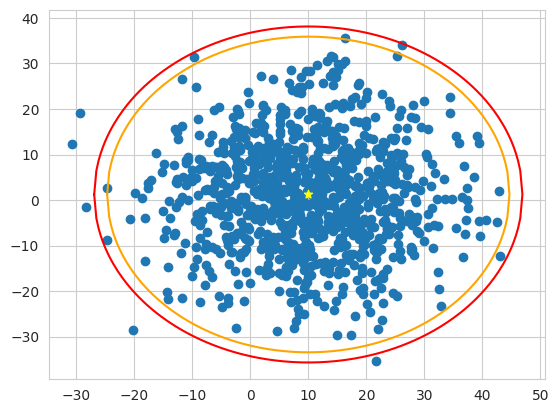

Draw histograms with 10 buckets for each dimension.

**Hint** use `plt.hist2d`

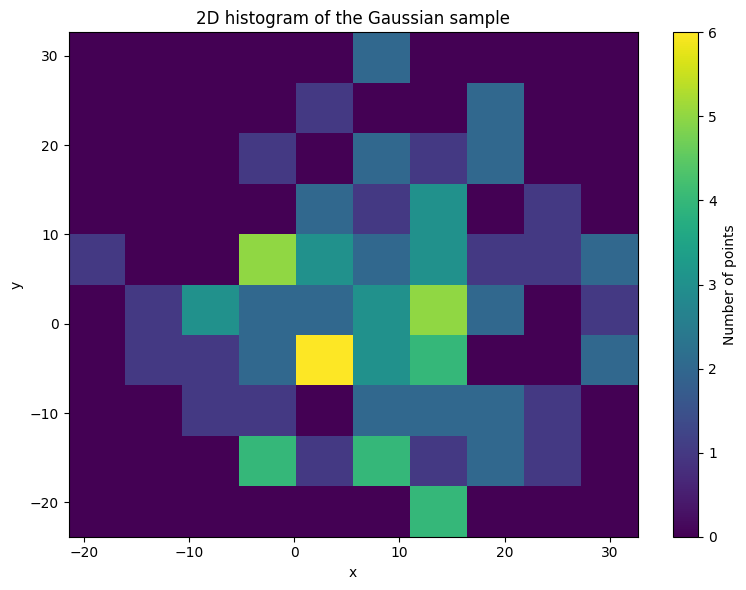

In [86]:
plt.figure(figsize=(8, 6))
hist = plt.hist2d(data[:, 0], data[:, 1], bins=10)
plt.colorbar(hist[3], label="Number of points")
plt.title("2D histogram of the Gaussian sample")
plt.xlabel('x')
plt.ylabel('y')
plt.tight_layout()
plt.show()

### Task 2 (2.5 points)

Upload the dataset  [fischer's irises](https://ru.wikipedia.org/wiki/Ирисы_Фишера).

In [87]:
import pandas as pd
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
X, y = iris.data, iris.target
X.sample(3)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
6,4.6,3.4,1.4,0.3
123,6.3,2.7,4.9,1.8
107,7.3,2.9,6.3,1.8


Compute correlation between features

In [88]:
corr = X.corr()
corr

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.000000,-0.117570,0.871754,0.817941
sepal width (cm),-0.117570,1.000000,-0.428440,-0.366126
petal length (cm),0.871754,-0.428440,1.000000,0.962865
petal width (cm),0.817941,-0.366126,0.962865,1.000000


To make investigating correlation more convenient build a **heatmap** using matplotlib.

Rows and columns should be signed with feature names.  The positive correlation should be displayed in green, the reverse in red, and the absence of correlation in white. Make the plot big enough.

**Hint:** use `plt.xticks`, `plt.yticks`, `plt.imshow`, `plt.colorbar`

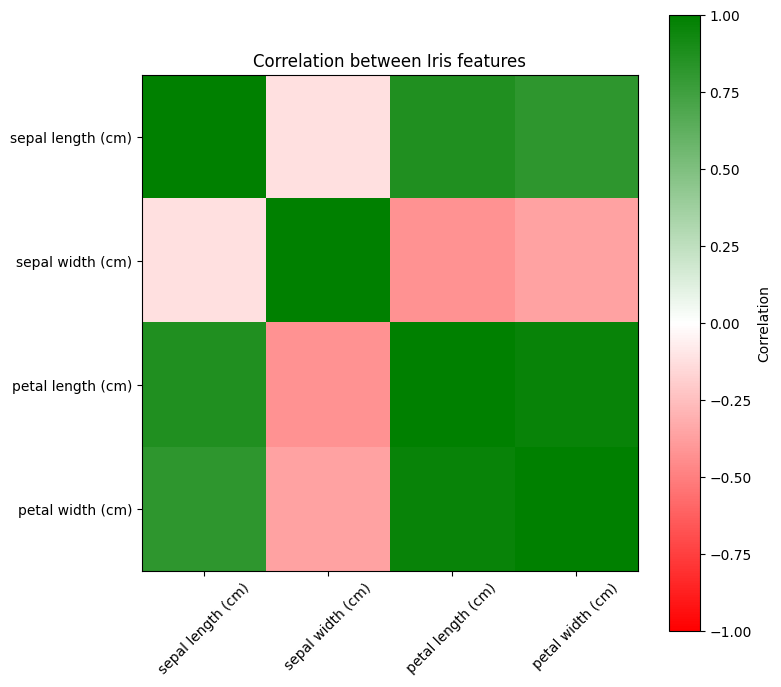

In [89]:
from matplotlib.colors import LinearSegmentedColormap

colors = ['red', 'white', 'green'] #создаем свою цветовую карту
cmap = LinearSegmentedColormap.from_list('corr_colors', colors) #создаем плавную цветовую шкалу
plt.figure(figsize=(8, 8))
plt.imshow(corr, cmap=cmap, vmin=-1, vmax=1)
plt.xticks(np.arange(len(X.columns)), X.columns, rotation = 45)
plt.yticks(np.arange(len(X.columns)), X.columns)
plt.colorbar(label = 'Correlation' )
plt.title('Correlation between Iris features')
plt.show()

Build the same heatmap using seaborn.heatmap

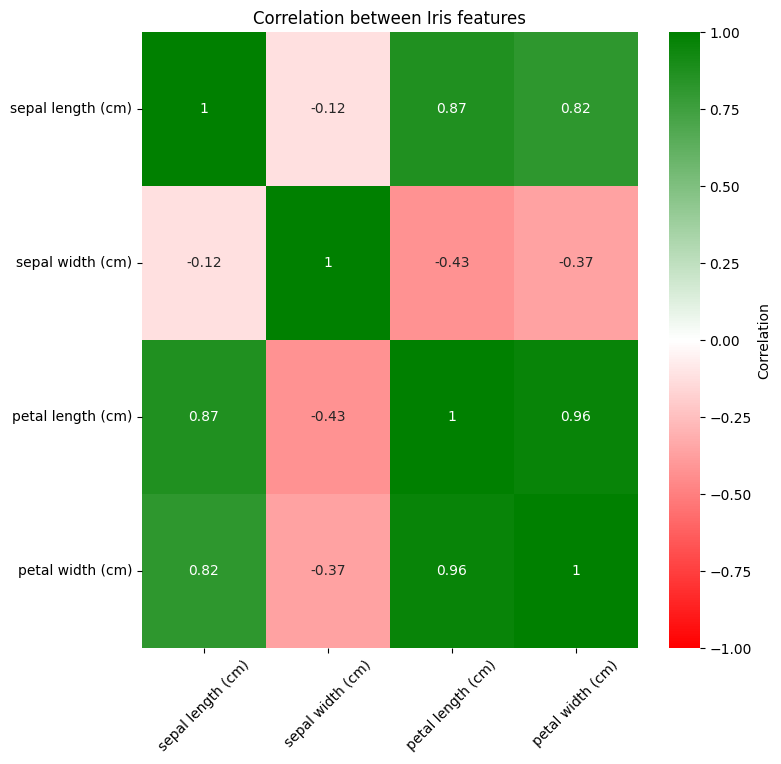

In [90]:
import seaborn as sns

plt.figure(figsize=(8, 8))
sns.heatmap(corr, cmap=cmap, vmin=-1, vmax=1, annot=True, cbar_kws={'label': 'Correlation'})
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.title('Correlation between Iris features')
plt.show()